# DX799 Capstone — Week 11: DBSCAN and Hierarchical Clustering

Density-based and hierarchical clustering were applied to Statlog Heart Disease and Framingham to examine whether cardiovascular measurements form stable patient subgroups. The analysis compares cluster structure, sensitivity to modeling choices, and observed disease rates without using the outcomes to construct clusters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEED = 42
SIL_SAMPLE = 800
HAC_MAX = 900
HAC_K = range(2, 6)
LINKAGES = ["single", "complete", "average", "ward"]

## 1. Data and exploratory analysis

The same five Statlog and six Framingham continuous predictors from Week 10 are used. Disease outcomes are excluded from clustering and examined only after groups have been formed. Standardization makes distance comparisons less dependent on measurement units.

In [2]:
BASE = "https://raw.githubusercontent.com/piraterashik/DX799-Data-Science-Capstone/main/"
heart = pd.read_csv(BASE + "preprocessed_heart_disease.csv")
framingham = pd.read_csv(BASE + "preprocessed_framingham.csv")

SPEC = {
    "Statlog": {"df": heart, "target": "target",
                "features": ["age", "trestbps", "chol", "thalach", "oldpeak"]},
    "Framingham": {"df": framingham, "target": "TenYearCHD",
                   "features": ["age", "sysBP", "diaBP", "BMI", "totChol", "glucose"]}
}

DATA = {}
eda_rows = []
for name, item in SPEC.items():
    required = item["features"] + [item["target"]]
    missing_cols = sorted(set(required) - set(item["df"].columns))
    if missing_cols:
        raise ValueError(f"{name}: missing columns {missing_cols}")
    raw = item["df"][item["features"]].apply(pd.to_numeric, errors="coerce")
    target = pd.to_numeric(item["df"][item["target"]], errors="coerce")
    valid = target.notna()
    raw, target = raw.loc[valid], target.loc[valid]
    x_raw = SimpleImputer(strategy="median").fit_transform(raw)
    x_scaled = StandardScaler().fit_transform(x_raw)
    DATA[name] = {"X": x_scaled, "raw": x_raw, "y": target.to_numpy(),
                  "features": item["features"]}
    for feature in item["features"]:
        values = raw[feature]
        q1, q3 = values.quantile([0.25, 0.75]); iqr = q3 - q1
        count = int(((values < q1 - 1.5 * iqr) |
                     (values > q3 + 1.5 * iqr)).sum()) if iqr > 0 else 0
        eda_rows.append({"Dataset": name, "Feature": feature,
                         "Missing": int(values.isna().sum()),
                         "Mean": values.mean(), "SD": values.std(),
                         "IQR outliers": count})

eda = pd.DataFrame(eda_rows)
display(eda.round(2))
for name, item in DATA.items():
    print(f"{name}: n={len(item['X'])}; outcome prevalence={np.mean(item['y']):.1%}")

,Dataset,Feature,Missing,Mean,SD,IQR outliers
0,Statlog,age,0,54.43,9.11,0
1,Statlog,trestbps,0,131.34,17.86,9
2,Statlog,chol,0,249.66,51.69,5
3,Statlog,thalach,0,149.68,23.17,1
4,Statlog,oldpeak,0,1.05,1.15,4
5,Framingham,age,0,49.58,8.57,0
6,Framingham,sysBP,0,132.35,22.04,126
7,Framingham,diaBP,0,82.89,11.91,81
8,Framingham,BMI,0,25.80,4.07,97
9,Framingham,totChol,0,236.69,44.33,57


Statlog: n=270; outcome prevalence=44.4%
Framingham: n=4238; outcome prevalence=15.2%


## 2. DBSCAN: neighborhoods and point types

DBSCAN defines a neighborhood using the radius **epsilon (eps)**. A **core** point has at least **MinPts** observations inside that radius, including itself. A **border** point is within the radius of a core point but is not itself core. Unconnected points are **noise** (label −1). A cluster consists of connected core points and their reachable border points.

,x,y,Cluster,Point type
0,0.00,0.0,0,Core
1,0.10,0.0,0,Core
2,0.00,0.1,0,Core
3,0.10,0.1,0,Core
4,-0.10,0.0,0,Core
5,0.35,0.0,0,Border
6,3.00,3.0,-1,Noise


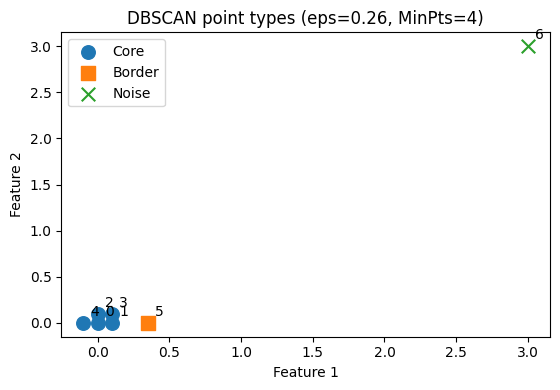

In [3]:
demo = np.array([[0, 0], [.1, 0], [0, .1], [.1, .1], [-.1, 0],
                 [.35, 0], [3, 3]], dtype=float)
demo_model = DBSCAN(eps=.26, min_samples=4).fit(demo)
core_idx = set(demo_model.core_sample_indices_)
demo_labels = demo_model.labels_
demo_types = ["Noise" if label == -1 else ("Core" if i in core_idx else "Border")
              for i, label in enumerate(demo_labels)]
display(pd.DataFrame({"x": demo[:, 0], "y": demo[:, 1],
                      "Cluster": demo_labels, "Point type": demo_types}))
fig, ax = plt.subplots(figsize=(5.7, 4))
for typ, marker in [("Core", "o"), ("Border", "s"), ("Noise", "x")]:
    sel = np.array(demo_types) == typ
    ax.scatter(demo[sel, 0], demo[sel, 1], marker=marker, s=95, label=typ)
for i, (x, y) in enumerate(demo):
    ax.annotate(str(i), (x, y), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="DBSCAN point types (eps=0.26, MinPts=4)")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Epsilon selection and density structure

Epsilon candidates are drawn from the distribution of each observation's distance to its MinPts-th nearest neighbor. Small radii may classify many observations as noise; large radii can merge distinct groups. MinPts values of 5, 10, and 20 are compared.

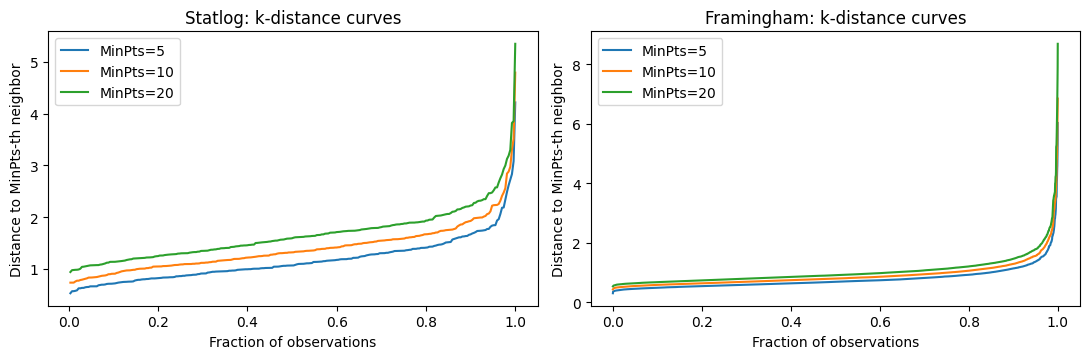

,Dataset,MinPts,eps,Clusters,Noise %,Core,Border,Smallest cluster,Silhouette (non-noise)
0,Statlog,5,0.786,3,73.333,41,31,5,0.058
1,Statlog,5,0.913,3,48.519,81,58,5,0.092
2,Statlog,5,1.020,3,37.778,122,46,4,0.242
3,Statlog,5,1.176,2,19.259,162,56,13,0.190
4,Statlog,5,1.352,1,11.111,202,38,240,NaN
5,Statlog,5,1.670,1,4.074,243,16,259,NaN
6,Statlog,5,2.174,1,0.741,261,7,268,NaN
7,Statlog,10,0.997,1,62.593,41,60,101,NaN
8,Statlog,10,1.118,1,44.074,81,70,151,NaN
9,Statlog,10,1.274,2,26.667,122,76,8,0.242


In [4]:
MINPTS = [5, 10, 20]
EPS_QUANTILES = [0.15, 0.30, 0.45, 0.60, 0.75, 0.90, 0.97]
DB_RESULTS = {}
DBSCAN_ROWS = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))

for ax, (name, info) in zip(axes, DATA.items()):
    X = info["X"]
    for pts in MINPTS:
        dists, _ = NearestNeighbors(n_neighbors=pts).fit(X).kneighbors(X)
        kth = np.sort(dists[:, -1])
        ax.plot(np.arange(1, len(X) + 1) / len(X), kth, label=f"MinPts={pts}")
        eps_values = np.unique(np.round(np.quantile(kth, EPS_QUANTILES), 4))
        for eps in eps_values:
            model = DBSCAN(eps=max(float(eps), .0001), min_samples=pts).fit(X)
            labels = model.labels_
            cluster_labels = np.unique(labels[labels >= 0])
            n_clusters = len(cluster_labels)
            valid = labels >= 0
            counts = pd.Series(labels[valid]).value_counts()
            core = len(model.core_sample_indices_)
            border = int(valid.sum()) - core
            sil = np.nan
            if n_clusters >= 2 and valid.sum() > n_clusters and counts.min() >= 2:
                try:
                    sil = silhouette_score(X[valid], labels[valid],
                                           sample_size=min(SIL_SAMPLE, valid.sum()),
                                           random_state=SEED)
                except ValueError:
                    pass
            row = {"Dataset": name, "MinPts": pts, "eps": eps,
                   "Clusters": n_clusters,
                   "Noise %": 100 * np.mean(labels == -1),
                   "Core": core, "Border": border,
                   "Smallest cluster": int(counts.min()) if len(counts) else 0,
                   "Silhouette (non-noise)": sil}
            DBSCAN_ROWS.append(row)
            DB_RESULTS[(name, pts, float(eps))] = (labels, model)
    ax.set(title=f"{name}: k-distance curves", xlabel="Fraction of observations",
           ylabel="Distance to MinPts-th neighbor")
    ax.legend()
plt.tight_layout(); plt.show()

dbscan_search = pd.DataFrame(DBSCAN_ROWS)
display(dbscan_search.round(3))

## 4. DBSCAN model selection and sensitivity

Candidate solutions are evaluated by separation, noise fraction, and smallest cluster size. A high silhouette among only a few non-noise points is not sufficient evidence of useful grouping. If no well-covered, nontrivial partition is found, that limitation is retained rather than treated as a successful classification.

In [5]:
DB_CHOICE, DB_LABELS = {}, {}
choice_rows = []
for name, info in DATA.items():
    s = dbscan_search[dbscan_search["Dataset"] == name].copy()
    n = len(info["X"])
    eligible = s[(s["Clusters"] >= 2) &
                 (s["Noise %"] <= 40) &
                 (s["Smallest cluster"] >= max(5, int(.01 * n))) &
                 s["Silhouette (non-noise)"].notna()]
    if len(eligible):
        row = eligible.sort_values(["Silhouette (non-noise)", "Noise %"],
                                   ascending=[False, True]).iloc[0]
        note = "Meets coverage and minimum cluster-size criteria"
    else:
        alternative = s[(s["Clusters"] >= 2) &
                        s["Silhouette (non-noise)"].notna()]
        if len(alternative):
            row = alternative.sort_values(["Noise %", "Silhouette (non-noise)"],
                                          ascending=[True, False]).iloc[0]
            note = "Exploratory only; at least one quality criterion was unmet"
        else:
            row = s.assign(deviation=(s["Noise %"] - 25).abs()).sort_values(
                ["deviation", "Clusters"]).iloc[0]
            note = "No multi-cluster candidate; illustrative density partition only"
    key = (name, int(row["MinPts"]), float(row["eps"]))
    labels, model = DB_RESULTS[key]
    DB_CHOICE[name] = {"eps": key[2], "MinPts": key[1], "note": note}
    DB_LABELS[name] = labels
    choice_rows.append({**row.to_dict(), "Selection note": note})

dbscan_choice = pd.DataFrame(choice_rows)
display(dbscan_choice.round(3))

,Dataset,MinPts,eps,Clusters,Noise %,Core,Border,Smallest cluster,Silhouette (non-noise),Selection note
0,Statlog,10,1.274,2,26.667,122,76,8,0.242,Meets coverage and minimum cluster-size criteria
1,Framingham,10,0.860,2,21.449,2543,786,7,0.284,Exploratory only; at least one quality criteri...


## 5. Core, border, noise, and clinical profiles

DBSCAN clusters are described using their original clinical measurements. Outcome rates are tabulated afterward and are not inputs to the clustering. Noise means low density in the chosen feature space, not necessarily an erroneous record or a medically abnormal patient.

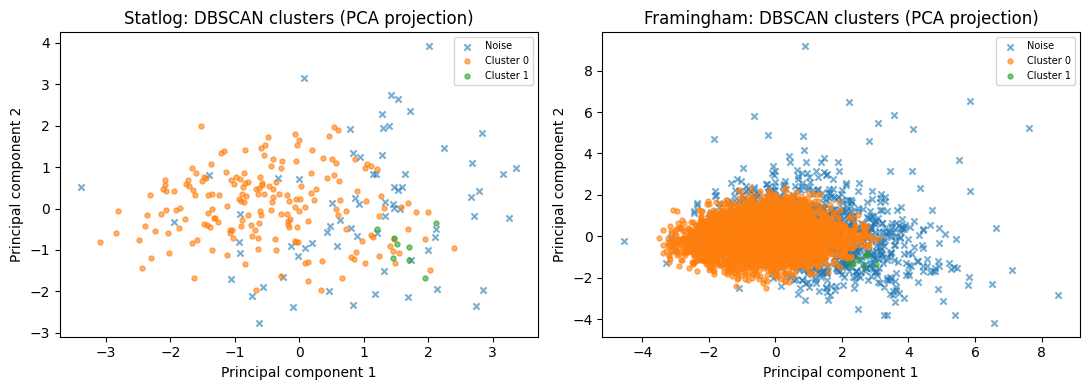

,Dataset,Group,Patients,Percent,Outcome rate,age,trestbps,chol,thalach,oldpeak,sysBP,diaBP,BMI,totChol,glucose
0,Statlog,Noise,72,26.667,0.653,57.153,140.958,263.486,136.236,1.674,NaN,NaN,NaN,NaN,NaN
1,Statlog,Cluster 0,190,70.370,0.347,53.142,127.921,243.463,156.842,0.793,NaN,NaN,NaN,NaN,NaN
2,Statlog,Cluster 1,8,2.963,0.875,60.625,126.125,272.375,100.500,1.537,NaN,NaN,NaN,NaN,NaN
3,Framingham,Noise,909,21.449,0.267,53.946,NaN,NaN,NaN,NaN,151.416,90.490,28.013,253.105,94.993
4,Framingham,Cluster 0,3322,78.386,0.120,48.385,NaN,NaN,NaN,NaN,127.044,80.771,25.185,232.182,77.963
5,Framingham,Cluster 1,7,0.165,0.429,52.714,NaN,NaN,NaN,NaN,176.143,103.500,30.211,244.286,70.429


In [6]:
db_profile_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, info) in zip(axes, DATA.items()):
    X = info["X"]; labels = DB_LABELS[name]
    coords = PCA(n_components=2, random_state=SEED).fit_transform(X)
    for group in np.unique(labels):
        mask = labels == group
        label_text = "Noise" if group == -1 else f"Cluster {group}"
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   s=13 if group >= 0 else 20, alpha=.6,
                   label=label_text, marker="x" if group == -1 else "o")
        profile = {"Dataset": name, "Group": label_text,
                   "Patients": int(mask.sum()), "Percent": 100 * mask.mean(),
                   "Outcome rate": float(np.mean(info["y"][mask]))}
        profile.update(dict(zip(info["features"], info["raw"][mask].mean(axis=0))))
        db_profile_rows.append(profile)
    ax.set(title=f"{name}: DBSCAN clusters (PCA projection)",
           xlabel="Principal component 1", ylabel="Principal component 2")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
dbscan_profiles = pd.DataFrame(db_profile_rows)
display(dbscan_profiles.round(3))

## 6. Epsilon sensitivity

The selected DBSCAN solution is refitted at 90% and 110% of its epsilon value. Changes in group count, noise percentage, and adjusted Rand index (ARI) indicate whether assignments depend strongly on small radius adjustments. ARI includes noise labels in this comparison.

In [7]:
db_sensitivity_rows = []
for name, item in DATA.items():
    reference = DB_LABELS[name]
    selected = DB_CHOICE[name]
    for factor in [.9, 1., 1.1]:
        eps = max(selected["eps"] * factor, .0001)
        labels = DBSCAN(eps=eps, min_samples=selected["MinPts"]).fit_predict(item["X"])
        db_sensitivity_rows.append({"Dataset": name, "Epsilon multiplier": factor,
            "eps": eps, "Clusters": len(set(labels) - {-1}),
            "Noise %": 100 * np.mean(labels == -1),
            "ARI vs selected": adjusted_rand_score(reference, labels)})
dbscan_sensitivity = pd.DataFrame(db_sensitivity_rows)
display(dbscan_sensitivity.round(3))

,Dataset,Epsilon multiplier,eps,Clusters,Noise %,ARI vs selected
0,Statlog,0.9,1.147,1,40.370,0.582
1,Statlog,1.0,1.274,2,26.667,1.000
2,Statlog,1.1,1.402,1,13.704,0.424
3,Framingham,0.9,0.774,3,31.406,0.614
4,Framingham,1.0,0.860,2,21.449,1.000
5,Framingham,1.1,0.945,1,14.889,0.703


## 7. Hierarchical agglomerative clustering

Hierarchical agglomerative clustering (HAC) starts with individual observations and repeatedly merges groups. **Single** linkage uses the closest pair of points; **complete** the farthest pair; **average** the average pairwise distance; **Ward** selects merges that minimize the increase in within-cluster squared error. Ward uses Euclidean geometry.

Because HAC builds a pairwise hierarchy, Framingham is evaluated on a reproducible 900-person subsample; all 270 Statlog records are used.

In [8]:
HAC_DATA = {}
for name, info in DATA.items():
    rng = np.random.default_rng(SEED)
    idx = np.sort(rng.choice(len(info["X"]), size=min(HAC_MAX, len(info["X"])),
                             replace=False))
    HAC_DATA[name] = {"X": info["X"][idx], "raw": info["raw"][idx],
                      "y": info["y"][idx], "indices": idx,
                      "features": info["features"]}

hac_rows = []
HAC_MODELS = {}
for name, info in HAC_DATA.items():
    X = info["X"]
    for method in LINKAGES:
        for k in HAC_K:
            model = AgglomerativeClustering(n_clusters=k, linkage=method)
            labels = model.fit_predict(X)
            sizes = np.bincount(labels)
            score = silhouette_score(X, labels, random_state=SEED,
                                     sample_size=min(SIL_SAMPLE, len(X)))
            hac_rows.append({"Dataset": name, "Linkage": method,
                             "k": k, "Silhouette": score,
                             "Smallest cluster": int(sizes.min()),
                             "Largest cluster": int(sizes.max())})
            HAC_MODELS[(name, method, k)] = labels
hac_search = pd.DataFrame(hac_rows)
display(hac_search.sort_values(["Dataset", "Silhouette"],
                               ascending=[True, False]).round(3))

,Dataset,Linkage,k,Silhouette,Smallest cluster,Largest cluster
16,Framingham,single,2,0.763,1,899
20,Framingham,complete,2,0.722,4,896
24,Framingham,average,2,0.722,4,896
25,Framingham,average,3,0.650,1,895
21,Framingham,complete,3,0.646,1,895
17,Framingham,single,3,0.640,1,898
22,Framingham,complete,4,0.625,1,894
26,Framingham,average,4,0.625,1,894
27,Framingham,average,5,0.623,1,894
18,Framingham,single,4,0.618,1,897


## 8. Dendrograms and linkage behavior

A dendrogram shows the order and distances at which observations merge. Large vertical gaps can suggest a tree cut; here, the largest merge-distance gap corresponding to k=2–5 supplies an illustrative cutoff. The four linkages are compared on identical 250-person subsets. A gap may also reflect an isolated observation rather than a meaningful patient group.

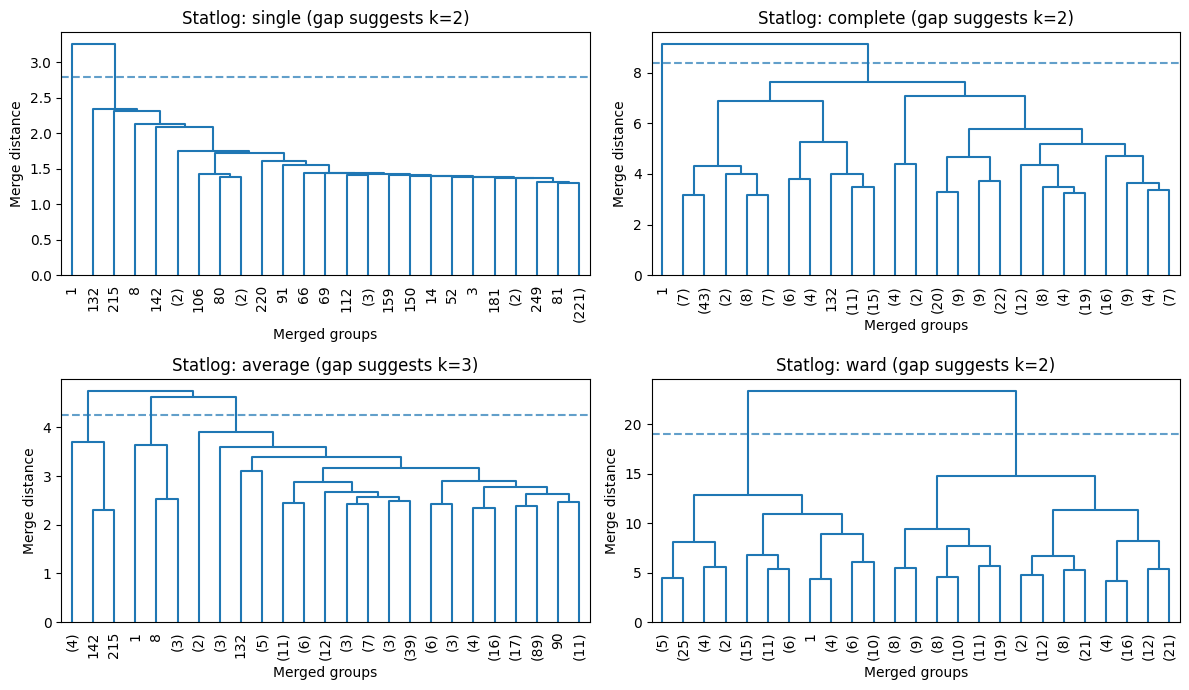

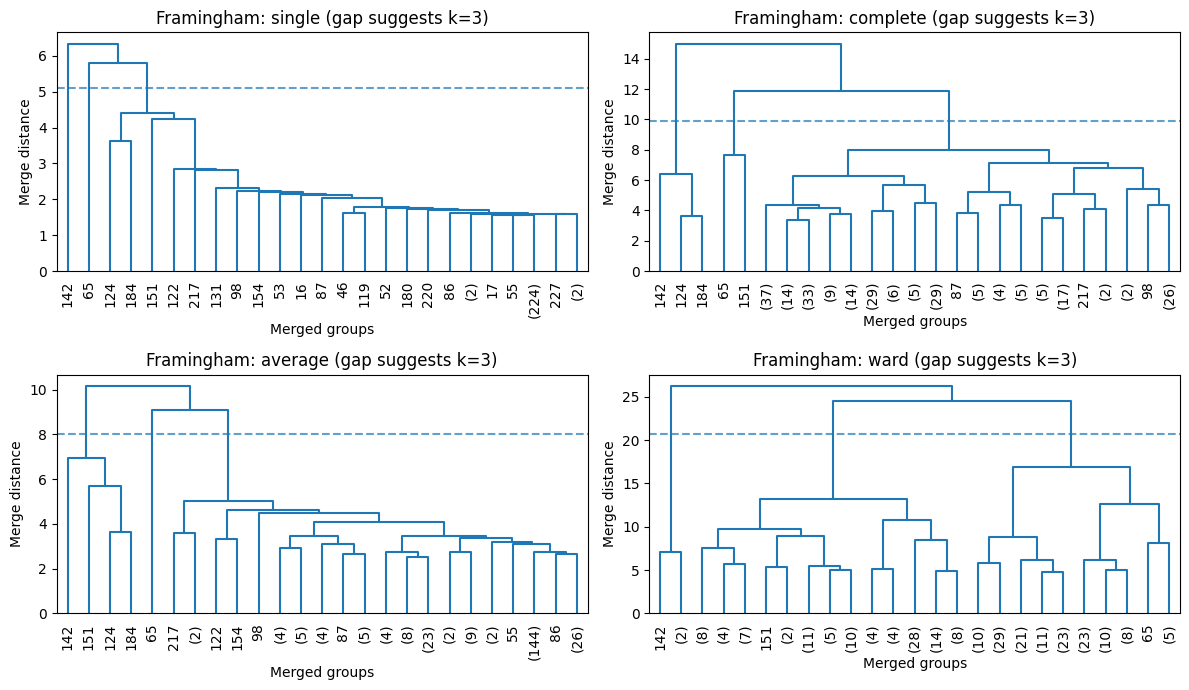

,Dataset,Linkage,Suggested k (merge gap),Actual clusters,Largest gap,Cut silhouette
0,Statlog,single,2,2,0.923,0.549
1,Statlog,complete,2,2,1.515,0.549
2,Statlog,average,3,3,0.718,0.330
3,Statlog,ward,2,2,8.667,0.223
4,Framingham,single,3,3,1.376,0.639
5,Framingham,complete,3,3,3.901,0.605
6,Framingham,average,3,3,2.139,0.653
7,Framingham,ward,3,3,7.610,0.214


In [9]:
DENDRO_N = 250
dendrogram_rows = []
for name, info in HAC_DATA.items():
    rng = np.random.default_rng(SEED)
    idx = np.sort(rng.choice(len(info["X"]), size=min(DENDRO_N, len(info["X"])),
                             replace=False))
    X = info["X"][idx]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, method in zip(axes.ravel(), LINKAGES):
        Z = linkage(X, method=method, metric="euclidean", optimal_ordering=False)
        gaps = {k: float(Z[-(k-1), 2] - Z[-k, 2]) for k in HAC_K}
        suggested_k = max(gaps, key=gaps.get)
        cut_height = (Z[-(suggested_k-1), 2] + Z[-suggested_k, 2]) / 2
        group_labels = fcluster(Z, t=suggested_k, criterion="maxclust")
        actual_k = len(np.unique(group_labels))
        score = (silhouette_score(X, group_labels) if 1 < actual_k < len(X)
                 else np.nan)
        dendrogram_rows.append({"Dataset": name, "Linkage": method,
            "Suggested k (merge gap)": suggested_k,
            "Actual clusters": actual_k, "Largest gap": gaps[suggested_k],
            "Cut silhouette": score})
        dendrogram(Z, truncate_mode="lastp", p=25, ax=ax,
                   leaf_rotation=90, show_leaf_counts=True, color_threshold=0)
        ax.axhline(cut_height, linestyle="--", alpha=.7)
        ax.set(title=f"{name}: {method} (gap suggests k={suggested_k})",
               xlabel="Merged groups", ylabel="Merge distance")
    plt.tight_layout(); plt.show()
dendrogram_summary = pd.DataFrame(dendrogram_rows)
display(dendrogram_summary.round(3))

## 9. Cluster selection and patient profiles

Candidate HAC partitions are compared using silhouette scores and group sizes. To limit solutions driven by isolated observations, the selected model must have at least five members in every cluster when possible. Clinical characteristics and disease prevalence are examined after clustering.

In [10]:
HAC_CHOICE, HAC_LABELS = {}, {}
selection_rows = []
hac_profile_rows = []
for name, info in HAC_DATA.items():
    s = hac_search[hac_search.Dataset == name]
    valid = s[s["Smallest cluster"] >= 5]
    best = (valid if len(valid) else s).sort_values("Silhouette", ascending=False).iloc[0]
    method, k = best["Linkage"], int(best["k"])
    labels = HAC_MODELS[(name, method, k)]
    HAC_CHOICE[name] = {"Linkage": method, "k": k}
    HAC_LABELS[name] = labels
    selection_rows.append(best.to_dict())
    for group in sorted(set(labels)):
        mask = labels == group
        row = {"Dataset": name, "Linkage": method, "k": k,
               "Cluster": group, "Patients": int(mask.sum()),
               "Outcome rate": float(info["y"][mask].mean())}
        row.update(dict(zip(info["features"], info["raw"][mask].mean(axis=0))))
        hac_profile_rows.append(row)
hac_choice = pd.DataFrame(selection_rows)
hac_profiles = pd.DataFrame(hac_profile_rows)
display(hac_choice.round(3))
display(hac_profiles.round(3))

,Dataset,Linkage,k,Silhouette,Smallest cluster,Largest cluster
0,Statlog,average,2,0.373,6,264
1,Framingham,ward,3,0.185,15,532


,Dataset,Linkage,k,Cluster,Patients,Outcome rate,age,trestbps,chol,thalach,oldpeak,sysBP,diaBP,BMI,totChol,glucose
0,Statlog,average,2,0,264,0.436,54.360,130.436,249.303,150.083,0.972,NaN,NaN,NaN,NaN,NaN
1,Statlog,average,2,1,6,0.833,57.667,171.333,265.333,131.833,4.467,NaN,NaN,NaN,NaN,NaN
2,Framingham,ward,3,0,532,0.188,53.726,NaN,NaN,NaN,NaN,140.481,87.512,26.980,251.024,78.976
3,Framingham,ward,3,1,353,0.054,42.595,NaN,NaN,NaN,NaN,118.698,75.965,23.785,216.972,79.921
4,Framingham,ward,3,2,15,0.400,56.600,NaN,NaN,NaN,NaN,149.067,87.467,28.519,243.000,215.667


## 10. Comparison with Week 10 K-means

K-means is refitted to the full standardized dataset using Week 10's chosen k (two for Statlog and three for Framingham). Its labels are compared with HAC on the corresponding matched subsample. ARI measures partition agreement, not predictive accuracy.

In [11]:
comparison_rows = []
for name, full in DATA.items():
    reference_k = 2 if name == "Statlog" else 3
    km_full = KMeans(n_clusters=reference_k, n_init=10, random_state=SEED).fit_predict(full["X"])
    idx = HAC_DATA[name]["indices"]
    hac_labels = HAC_LABELS[name]
    db_labels = DB_LABELS[name]
    comparison_rows.append({"Dataset": name,
        "KMeans k (Week 10)": reference_k,
        "HAC linkage": HAC_CHOICE[name]["Linkage"],
        "HAC k": HAC_CHOICE[name]["k"],
        "ARI: KMeans vs HAC (matched subset)": adjusted_rand_score(km_full[idx], hac_labels),
        "ARI: KMeans vs DBSCAN (full data)": adjusted_rand_score(km_full, db_labels),
        "DBSCAN noise %": 100 * np.mean(db_labels == -1)})
method_comparison = pd.DataFrame(comparison_rows)
display(method_comparison.round(3))

,Dataset,KMeans k (Week 10),HAC linkage,HAC k,ARI: KMeans vs HAC (matched subset),ARI: KMeans vs DBSCAN (full data),DBSCAN noise %
0,Statlog,2,average,2,0.019,0.218,26.667
1,Framingham,3,ward,3,0.327,0.173,21.449


## 11. Discussion

DBSCAN and hierarchical clustering identified different cardiovascular groupings, but both methods showed substantial sensitivity to their assumptions and parameter settings.

In Statlog, DBSCAN identified two clusters containing 190 and 8 patients, with 72 additional observations classified as noise. The noise group had a higher observed heart-disease rate (65.3%) than the largest cluster (34.7%). Framingham displayed a similar pattern, with CHD rates of 26.7% among noise observations and 12.0% in the largest cluster. However, the secondary Framingham cluster contained only seven patients and did not meet the minimum-size selection criterion.

Changes of 10% in epsilon substantially altered the DBSCAN partitions. Statlog's number of clusters changed from one to two and back to one, while Framingham produced between one and three clusters. These changes indicate that the identified density structures were sensitive to neighborhood radius.

Hierarchical clustering also demonstrated the importance of model selection. Average linkage produced the highest eligible silhouette score in Statlog (0.373), while Ward's linkage was selected for Framingham (0.185). However, the selected solutions contained clusters of just six and fifteen patients, respectively. Higher silhouette scores from other linkage methods sometimes resulted from isolating one or a few observations, illustrating why cluster size must be considered alongside separation.

Comparison with Week 10 showed limited agreement between methods. K-Means versus DBSCAN produced adjusted Rand indices of 0.218 for Statlog and 0.173 for Framingham, while K-Means versus HAC produced 0.019 and 0.327, respectively. These differences indicate that cluster assignments depend strongly on the algorithm and its assumptions.

Overall, density-based clustering distinguished relatively isolated cardiovascular profiles that exhibited higher observed disease rates. Nevertheless, small clusters, parameter sensitivity, and disagreement between algorithms limit the reliability of these partitions. The findings support exploratory patient characterization rather than validated clinical risk classification.

In [12]:
for name in DATA:
    d = dbscan_choice[dbscan_choice.Dataset == name].iloc[0]
    h = hac_choice[hac_choice.Dataset == name].iloc[0]
    sens = dbscan_sensitivity[dbscan_sensitivity.Dataset == name]
    print(f"{name}: DBSCAN eps={d['eps']:.3f}, MinPts={int(d['MinPts'])}, "
          f"clusters={int(d['Clusters'])}, noise={d['Noise %']:.1f}%, "
          f"core={int(d['Core'])}, border={int(d['Border'])}.")
    print(f"  Selection: {d['Selection note']}.")
    print(f"  Epsilon sensitivity: ARI range={sens['ARI vs selected'].min():.3f}–"
          f"{sens['ARI vs selected'].max():.3f}; noise range="
          f"{sens['Noise %'].min():.1f}%–{sens['Noise %'].max():.1f}%.")
    print(f"  HAC: linkage={h['Linkage']}, k={int(h['k'])}, "
          f"silhouette={h['Silhouette']:.3f}, "
          f"smallest group={int(h['Smallest cluster'])}.")
    selected_hac = hac_profiles[hac_profiles.Dataset == name]
    print(f"  HAC observed outcome rates: "
          f"{[round(v, 3) for v in selected_hac['Outcome rate'].tolist()]}." )

Statlog: DBSCAN eps=1.274, MinPts=10, clusters=2, noise=26.7%, core=122, border=76.
  Selection: Meets coverage and minimum cluster-size criteria.
  Epsilon sensitivity: ARI range=0.424–1.000; noise range=13.7%–40.4%.
  HAC: linkage=average, k=2, silhouette=0.373, smallest group=6.
  HAC observed outcome rates: [0.436, 0.833].
Framingham: DBSCAN eps=0.860, MinPts=10, clusters=2, noise=21.4%, core=2543, border=786.
  Selection: Exploratory only; at least one quality criterion was unmet.
  Epsilon sensitivity: ARI range=0.614–1.000; noise range=14.9%–31.4%.
  HAC: linkage=ward, k=3, silhouette=0.185, smallest group=15.
  HAC observed outcome rates: [0.188, 0.054, 0.4].


In [14]:

from math import sqrt

def wilson_interval(positive, total):
    z = 1.96
    p = positive / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = z * sqrt(
        p * (1-p) / total + z**2 / (4*total**2)
    ) / denominator
    return center - margin, center + margin

for name in DATA:
    labels = DB_LABELS[name]
    y = DATA[name]["y"]

    print(f"\n{name} DBSCAN:")

    for cluster in sorted(set(labels) - {-1}):
        mask = labels == cluster
        n = int(mask.sum())

        if n < 50:
            positive = int(y[mask].sum())
            low, high = wilson_interval(positive, n)

            print(
                f"Cluster {cluster}: {positive}/{n} positive; "
                f"95% interval {low:.3f} to {high:.3f}"
            )

    print(f"{name} HAC:")

    labels = HAC_LABELS[name]
    y = HAC_DATA[name]["y"]

    for cluster in np.unique(labels):
        mask = labels == cluster
        n = int(mask.sum())

        if n < 50:
            positive = int(y[mask].sum())
            low, high = wilson_interval(positive, n)

            print(
                f"Cluster {cluster}: {positive}/{n} positive; "
                f"95% interval {low:.3f} to {high:.3f}"
            )



Statlog DBSCAN:
Cluster 1: 7/8 positive; 95% interval 0.529 to 0.978
Statlog HAC:
Cluster 1: 5/6 positive; 95% interval 0.436 to 0.970

Framingham DBSCAN:
Cluster 1: 3/7 positive; 95% interval 0.158 to 0.750
Framingham HAC:
Cluster 2: 6/15 positive; 95% interval 0.198 to 0.643


## References and limitations

**Data:** [Capstone dataset repository](https://github.com/piraterashik/DX799-Data-Science-Capstone) (preprocessed UCI Statlog Heart and Framingham data).

**Methods:** [Scikit-learn DBSCAN](https://scikit-learn.org/stable/modules/clustering.html#dbscan); [agglomerative clustering](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering); [SciPy hierarchical clustering](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html).

Outliers in a standardized feature space are not equivalent to clinically verified anomalies. The two datasets differ in population and outcome, so outcome rates should not be compared across datasets. Density thresholds and dendrogram cuts are exploratory choices, not validated patient-risk categories.

In [15]:
TABLES = {
    "week11_eda.csv": eda,
    "week11_dbscan_search.csv": dbscan_search,
    "week11_dbscan_selection.csv": dbscan_choice,
    "week11_dbscan_profiles.csv": dbscan_profiles,
    "week11_dbscan_sensitivity.csv": dbscan_sensitivity,
    "week11_hac_search.csv": hac_search,
    "week11_dendrogram_summary.csv": dendrogram_summary,
    "week11_hac_selection.csv": hac_choice,
    "week11_hac_profiles.csv": hac_profiles,
    "week11_method_comparison.csv": method_comparison
}
for filename, result in TABLES.items():
    result.to_csv(filename, index=False)